# Simulación de Monte Carlo y valoración de una call asiática

Se generan trayectorias de CAT, MRK y MSFT mediante un movimiento browniano geométrico correlacionado y se calcula el payoff de una call asiática a partir de la suma de sus medias geométricas temporales. La media de los payoffs descontados proporciona la prima inicial estimada.

- **Cartera:** CAT, MRK y MSFT, en ese orden en todas las matrices.
- **Simulación:** 100.000 trayectorias, 20 pasos trimestrales y cinco años.
- **Contrato:** precios iniciales normalizados $S_0=[1,1,1]$, tipo libre de riesgo del 1 %, sin dividendos y strike 3.
- **Supuestos:** volatilidades y correlaciones constantes durante la simulación.
- **Reproducibilidad:** semilla 42; se muestran las primeras cinco trayectorias.

**Entradas:** parámetros históricos incorporados en el notebook. **Dependencias:** NumPy, pandas, Matplotlib e IPython. La ejecución se realiza de arriba abajo y no requiere archivos de datos externos ni conexión a internet.


In [1]:
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.options.display.float_format = "{:.6f}".format
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["axes.prop_cycle"] = plt.cycler(
    color=["#004481", "#2DCCCD", "#1973B8", "#5AC4C4", "#B2DFF4"]
)


## 1. Cartera y parámetros históricos

Las volatilidades anuales y las correlaciones proceden de la selección de cartera realizada sobre `Datos/Transformados/dowjones_diario_2016_2025.csv`. Se emplean los rendimientos logarítmicos diarios del **05/01/2016 al 31/12/2025**. La volatilidad se anualizó con **252 sesiones bursátiles** y la correlación se calculó con el coeficiente de Pearson.

Se incorporan los valores de `outputs/parametros_montecarlo.json` con la precisión de seis decimales utilizada por el equipo. Estos archivos documentan la procedencia de los parámetros y no son necesarios para ejecutar el notebook.

El histórico se utiliza para estimar las volatilidades y las correlaciones. El crecimiento esperado de las trayectorias se fija en la tasa libre de riesgo, de acuerdo con el marco de valoración neutral al riesgo.


In [2]:
activos = ["CAT", "MRK", "MSFT"]

# Parámetros calculados por el equipo sobre los rendimientos logarítmicos.
sigma = np.array([0.304449, 0.226614, 0.267572])
rho = np.array([
    [1.0, 0.249833, 0.394764],
    [0.249833, 1.0, 0.276564],
    [0.394764, 0.276564, 1.0],
])


## 2. Configuración de la simulación

El horizonte de cinco años se divide en **20 pasos de 0,25 años**. Los instantes simulados son $t_j=j\Delta t$, con $j=1,\ldots,20$: desde $t=0,25$ hasta $t=5$.

El precio inicial $S_0$ corresponde a $t=0$ y se incluye en la representación de las trayectorias. Las medias geométricas del payoff utilizan las 20 observaciones futuras, sin añadir el precio inicial como una observación más.

La tasa libre de riesgo es $r=0,01$ para los tres activos. Las volatilidades anuales y el tipo de interés se expresan en fracción, por lo que **0,01 equivale al 1 %**. Se eligen 100.000 simulaciones para reducir el error de muestreo de Monte Carlo y se fija la semilla 42 para reproducir los resultados.


In [3]:
num_sims = 100_000
num_pasos = 20
TTM = 5
dt = TTM / num_pasos
S0 = np.ones(3)
r = 0.01
strike = 3
semilla = 42

df_configuracion = pd.DataFrame({
    "Simulaciones": [num_sims], "Pasos": [num_pasos],
    "Horizonte (años)": [TTM], "Paso (años)": [dt],
    "Tipo libre de riesgo": [r], "Strike": [strike], "Semilla": [semilla],
})
df_activos = pd.DataFrame(
    {"S0 normalizado": S0, "Volatilidad anual": sigma},
    index=pd.Index(activos, name="Activo"),
)
df_correlacion = pd.DataFrame(rho, index=activos, columns=activos)

display(Markdown("**Configuración de la simulación (r en fracción: 0.01 = 1 %)**"), df_configuracion)
display(Markdown("**Parámetros de las acciones (volatilidad anual en fracción)**"), df_activos.round(6))
display(Markdown("**Matriz de correlaciones**"), df_correlacion.round(6))


**Configuración de la simulación (r en fracción: 0.01 = 1 %)**

,Simulaciones,Pasos,Horizonte (años),Paso (años),Tipo libre de riesgo,Strike,Semilla
0,100000,20,5,0.250000,0.010000,3,42


**Parámetros de las acciones (volatilidad anual en fracción)**

,S0 normalizado,Volatilidad anual
Activo,,
CAT,1.000000,0.304449
MRK,1.000000,0.226614
MSFT,1.000000,0.267572


**Matriz de correlaciones**

,CAT,MRK,MSFT
CAT,1.000000,0.249833,0.394764
MRK,0.249833,1.000000,0.276564
MSFT,0.394764,0.276564,1.000000


## 3. Generación de la matriz de trayectorias X

Para cada activo $k$, el movimiento browniano geométrico se simula mediante:

$$
S_j^k=S_0^k\exp\left(
\sum_{\ell=1}^{j}
\left[
\left(r-\frac{\sigma_k^2}{2}\right)\Delta t
+\sigma_k\sqrt{\Delta t}\,Z_\ell^k
\right]
\right).
$$

Se generan normales estándar independientes y se aplica la descomposición de Cholesky $\rho=LL^\top$. Al organizar los vectores normales por filas, la multiplicación **Z @ L.T** incorpora las correlaciones entre CAT, MRK y MSFT. El término $\sqrt{\Delta t}\,Z$ representa los incrementos brownianos y $\sigma$ ajusta su magnitud para cada activo.

**np.cumsum** acumula los incrementos logarítmicos sobre el eje temporal y **np.exp** obtiene los precios normalizados. El cálculo de las 100.000 trayectorias se realiza con operaciones matriciales, sin bucles.

**X** tiene forma **(100000, 20, 3)**, con ejes **(simulación, instante, activo)**. El tiempo mostrado mide exclusivamente la generación de X, sin incluir las tablas, los gráficos ni el cálculo posterior del payoff.


In [4]:
inicio = perf_counter()
L = np.linalg.cholesky(rho)
rng = np.random.default_rng(semilla)
Z = rng.standard_normal((num_sims, num_pasos, 3)) @ L.T

incrementos = (r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z
X = S0 * np.exp(np.cumsum(incrementos, axis=1))
tiempo_simulacion = perf_counter() - inicio

tiempos = np.arange(1, num_pasos + 1) * dt
simulaciones = pd.Index(np.arange(1, num_sims + 1), name="Simulación")
anios = np.arange(1, TTM + 1)
indices_anuales = (anios / dt).astype(int) - 1

df_simulacion = pd.DataFrame({
    "Forma de X": [str(X.shape)],
    "Tiempo de generación (s)": [tiempo_simulacion],
})
display(Markdown("**Matriz completa generada con semilla 42**"), df_simulacion.round(4))


**Matriz completa generada con semilla 42**

,Forma de X,Tiempo de generación (s)
0,"(100000, 20, 3)",0.167400


## 4. Primeras cinco trayectorias y cierres anuales

La tabla recoge los precios normalizados de las primeras cinco simulaciones al cierre de los años **1, 2, 3, 4 y 5**. Las columnas **Simulación** y **Año** identifican cada observación. Estos años son tiempos relativos desde el inicio de la simulación, distintos de las fechas del histórico.

El gráfico representa un abanico de cinco trayectorias por activo, todas con origen en $S_0=1$. Se incluyen los 20 pasos trimestrales y el instante inicial. Las primeras cinco trayectorias son ejemplos visuales; la valoración utiliza las 100.000 simulaciones.


In [5]:
df_precios_anuales = pd.DataFrame(
    X[:5, indices_anuales, :].reshape(25, 3),
    index=pd.MultiIndex.from_product(
        [simulaciones[:5], anios], names=["Simulación", "Año"]
    ),
    columns=activos,
).reset_index()
display(
    Markdown("**Primeras cinco simulaciones: precios normalizados al cierre de cada año**"),
    df_precios_anuales.round(4),
)


**Primeras cinco simulaciones: precios normalizados al cierre de cada año**

,Simulación,Año,CAT,MRK,MSFT
0,1,1,1.043800,0.765400,0.967700
1,1,2,0.919200,0.992900,0.882900
2,1,3,1.074700,1.043600,1.120100
3,1,4,1.050600,1.150300,1.132200
4,1,5,1.445400,0.880600,1.259000
5,2,1,0.751600,0.809400,0.938300
6,2,2,0.696100,0.740300,0.929500
7,2,3,0.612900,0.655000,0.684800
8,2,4,0.386500,0.500600,0.583100
9,2,5,0.445500,0.444200,0.518600


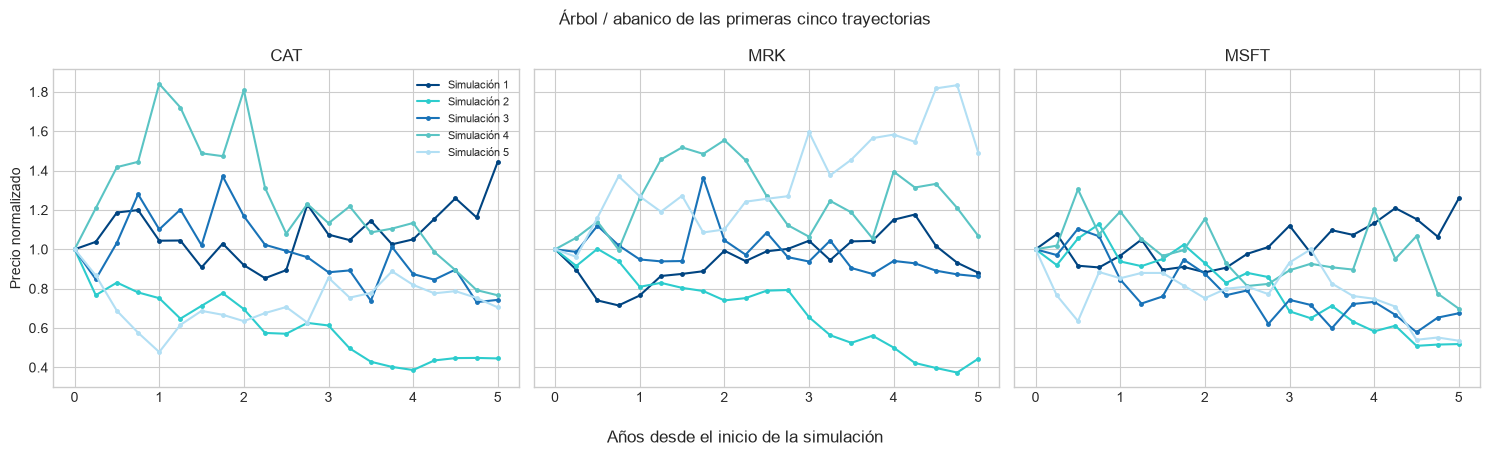

In [6]:
tiempos_con_t0 = np.r_[0, tiempos]
X_ejemplos = np.concatenate((
    np.broadcast_to(S0, (5, 1, 3)), X[:5]
), axis=1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
axes[0].plot(tiempos_con_t0, X_ejemplos[:, :, 0].T, marker="o", markersize=2.5)
axes[1].plot(tiempos_con_t0, X_ejemplos[:, :, 1].T, marker="o", markersize=2.5)
axes[2].plot(tiempos_con_t0, X_ejemplos[:, :, 2].T, marker="o", markersize=2.5)
axes[0].set_title(activos[0])
axes[1].set_title(activos[1])
axes[2].set_title(activos[2])
axes[0].set_ylabel("Precio normalizado")
axes[0].legend(np.char.add("Simulación ", np.arange(1, 6).astype(str)), fontsize=8)
fig.supxlabel("Años desde el inicio de la simulación")
fig.suptitle("Árbol / abanico de las primeras cinco trayectorias")
fig.tight_layout()
plt.show()


## 5. Cálculo del payoff y de la prima inicial

La opción es asiática porque su pago depende de los precios observados durante la trayectoria. Para cada simulación se calcula la media geométrica de los 20 precios normalizados de cada activo y, después, se suman las tres medias:

$$
G_k=\exp\left(\frac{1}{20}\sum_{j=1}^{20}
\ln\frac{S_j^k}{S_0^k}\right),
\qquad
V_T=\max(G_1+G_2+G_3-3,0).
$$

La media se toma **a lo largo del tiempo para cada activo**, no entre los tres activos en un mismo instante. La parte positiva del resultado aplica el strike 3 y garantiza un payoff no negativo.

Se obtiene un payoff para cada una de las 100.000 trayectorias. La prima inicial se estima descontando cada pago al tipo libre de riesgo y calculando su media:

$$
\widehat V_0=\frac{1}{N}\sum_{h=1}^{N}
V_T^{(h)}e^{-rT}.
$$

El resumen incluye la prima, el payoff medio, los porcentajes de pagos positivos y nulos y el error estándar de la media descontada. Los payoffs de cero también forman parte de la muestra utilizada para valorar.


In [7]:
medias_geometricas = np.exp(np.mean(np.log(X / S0), axis=1))
payoff = np.maximum(medias_geometricas.sum(axis=1) - strike, 0)
primas_t0 = payoff * np.exp(-r * TTM)
prima_t0 = primas_t0.mean()
error_estandar = primas_t0.std(ddof=1) / np.sqrt(num_sims)

df_payoffs = pd.DataFrame(
    medias_geometricas, index=simulaciones,
    columns=np.char.add("Media geométrica ", np.asarray(activos)),
)
df_payoffs["Suma de medias"] = medias_geometricas.sum(axis=1)
df_payoffs["Payoff final"] = payoff
df_payoffs["Prima individual t=0"] = primas_t0
display(Markdown("**Payoffs y primas de las primeras cinco trayectorias**"), df_payoffs.head(5).round(6))

df_resumen = pd.DataFrame({
    "Prima inicial media": [prima_t0],
    "Payoff medio final": [payoff.mean()],
    "Payoff positivo (%)": [100 * (payoff > 0).mean()],
    "Payoff cero (%)": [100 * (payoff == 0).mean()],
    "Error estándar de la prima": [error_estandar],
})
display(Markdown("**Resumen de las 100.000 simulaciones**"), df_resumen.round(6))


**Payoffs y primas de las primeras cinco trayectorias**

,Media geométrica CAT,Media geométrica MRK,Media geométrica MSFT,Suma de medias,Payoff final,Prima individual t=0
Simulación,,,,,,
1,1.076804,0.937171,1.024081,3.038057,0.038057,0.036200
2,0.574135,0.652194,0.768745,1.995074,0.000000,0.000000
3,0.966175,0.976440,0.765634,2.708248,0.000000,0.000000
4,1.221272,1.248165,0.971029,3.440466,0.440466,0.418984
5,0.709525,1.353225,0.761890,2.824640,0.000000,0.000000


**Resumen de las 100.000 simulaciones**

,Prima inicial media,Payoff medio final,Payoff positivo (%),Payoff cero (%),Error estándar de la prima
0,0.295072,0.310201,44.129000,55.871000,0.001624


## 6. Payoffs descontados por fecha: matriz Y

El valor descontado de cada trayectoria en un instante se obtiene descontando su payoff final hasta esa fecha:

$$
t_j=j\Delta t,\qquad
Y_{h,j}=V_T^{(h)}e^{-r(20-j)\Delta t}
       =V_T^{(h)}e^{-r(T-t_j)}.
$$

El código utiliza tiempos expresados en años. Por ello, **TTM - tiempos** ya es el tiempo restante hasta el vencimiento y no se vuelve a multiplicar por $\Delta t$.

**Y** tiene forma **(100000, 20)**. La fila $h$ mantiene la correspondencia con la trayectoria $h$ de X y la columna $j$ corresponde al mismo instante trimestral. En el vencimiento, $Y_{h,20}=V_T^{(h)}$.

**df_primas** conserva las 20 fechas y todas las simulaciones. **df_primas_anuales** muestra el valor descontado en $t=0$ y los cinco cierres anuales de las primeras cinco trayectorias, junto con la media de las 100.000 simulaciones.

Cada elemento de Y es un **payoff realizado descontado**. La prima inicial estimada es la media de esos valores en $t=0$. La evolución por fecha de una trayectoria refleja el descuento de su mismo payoff final.


In [8]:
Y = payoff[:, None] * np.exp(-r * (TTM - tiempos))[None, :]
df_primas = pd.DataFrame(
    Y, index=simulaciones, columns=pd.Index(tiempos, name="Año")
)

df_primas_anuales = pd.DataFrame(
    np.vstack((primas_t0[:5], Y[:5, indices_anuales].T)),
    index=pd.Index(np.r_[0, anios], name="Año"),
    columns=np.char.add("Simulación ", np.arange(1, 6).astype(str)),
)
df_primas_anuales["Media de 100.000"] = np.r_[
    prima_t0, Y[:, indices_anuales].mean(axis=0)
]
display(Markdown("**Primas por fecha: inicio y cierre de cada año**"), df_primas_anuales.round(6))


**Primas por fecha: inicio y cierre de cada año**

,Simulación 1,Simulación 2,Simulación 3,Simulación 4,Simulación 5,Media de 100.000
Año,,,,,,
0,0.036200,0.000000,0.000000,0.418984,0.000000,0.295072
1,0.036564,0.000000,0.000000,0.423195,0.000000,0.298038
2,0.036932,0.000000,0.000000,0.427448,0.000000,0.301033
3,0.037303,0.000000,0.000000,0.431744,0.000000,0.304059
4,0.037678,0.000000,0.000000,0.436083,0.000000,0.307114
5,0.038057,0.000000,0.000000,0.440466,0.000000,0.310201


## 7. Distribución de los payoffs positivos

Se representan solo los payoffs **mayores que cero**, para que la masa de ceros no oculte su distribución. Su porcentaje se indica en el título y en el resumen anterior. Los ceros **sí se incluyen** al calcular la prima media.


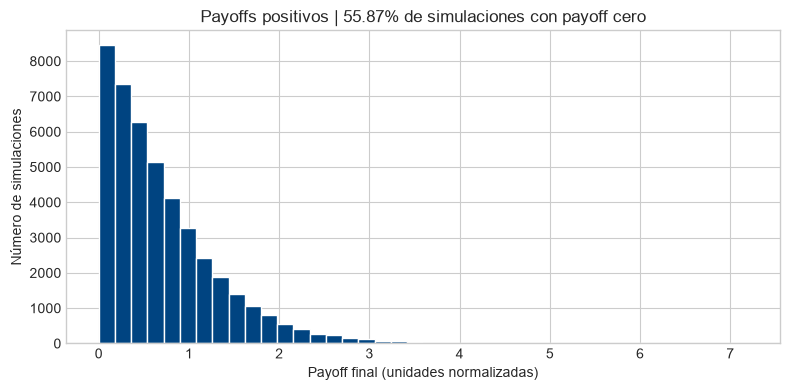

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(payoff[payoff > 0], bins=40, color="#004481", edgecolor="white")
ax.set_xlabel("Payoff final (unidades normalizadas)")
ax.set_ylabel("Número de simulaciones")
ax.set_title(
    f"Payoffs positivos | {(payoff == 0).mean():.2%} de simulaciones con payoff cero"
)
fig.tight_layout()
plt.show()


## 8. Organización de los resultados

Los precios, los retornos, los payoffs y los valores descontados se reúnen en **resultados_montecarlo**, junto con los parámetros utilizados. Se conserva la correspondencia entre cada trayectoria y sus resultados mediante **id_simulacion**.

Los retornos de cada paso se obtienen a partir de los precios simulados:

$$
R^{\log}_{h,j,k}=\ln\frac{S^k_{h,j}}{S^k_{h,j-1}},
\qquad
R^{\mathrm{simple}}_{h,j,k}=e^{R^{\log}_{h,j,k}}-1.
$$

En el primer paso se utiliza $S_0$ como precio anterior. Los retornos son **trimestrales**, sin anualizar, y conservan la forma **(100000, 20, 3)** y el orden **CAT, MRK, MSFT**.

La primera fila de cada array corresponde a la simulación 1. El primer paso representa $t=0.25$ y el último, $t=5$. Los arrays conservan los valores completos; el redondeo se aplica únicamente a las tablas mostradas.


In [10]:
retornos_log_simulados = np.diff(np.log(X / S0), axis=1, prepend=0.0)
retornos_simples_simulados = np.expm1(retornos_log_simulados)

resultados_montecarlo = {
    "X": X,
    "retornos_log": retornos_log_simulados,
    "retornos_simples": retornos_simples_simulados,
    "payoff": payoff,
    "Y": Y,
    "id_simulacion": simulaciones.to_numpy(),
    "tiempos": tiempos,
    "activos": np.asarray(activos),
    "S0": S0,
    "sigma": sigma,
    "rho": rho,
    "r": r,
    "TTM": TTM,
    "dt": dt,
    "strike": strike,
    "semilla": semilla,
    "num_sims": num_sims,
    "num_pasos": num_pasos,
    "periodo_estimacion": np.array(["2016-01-05", "2025-12-31"]),
}

df_resultados = pd.DataFrame({
    "Variable": ["X", "retornos_log", "retornos_simples", "payoff", "Y", "id_simulacion", "tiempos"],
    "Forma": [
        str(X.shape), str(retornos_log_simulados.shape),
        str(retornos_simples_simulados.shape), str(payoff.shape),
        str(Y.shape), str(simulaciones.shape), str(tiempos.shape),
    ],
    "Contenido": [
        "Precios normalizados", "Retornos logarítmicos trimestrales",
        "Retornos simples trimestrales", "Payoff final por trayectoria",
        "Payoff descontado por trayectoria e instante",
        "Identificadores de las trayectorias", "Instantes en años",
    ],
})
display(Markdown("**Estructura de los resultados de Monte Carlo**"), df_resultados)


**Estructura de los resultados de Monte Carlo**

,Variable,Forma,Contenido
0,X,"(100000, 20, 3)",Precios normalizados
1,retornos_log,"(100000, 20, 3)",Retornos logarítmicos trimestrales
2,retornos_simples,"(100000, 20, 3)",Retornos simples trimestrales
3,payoff,"(100000,)",Payoff final por trayectoria
4,Y,"(100000, 20)",Payoff descontado por trayectoria e instante
5,id_simulacion,"(100000,)",Identificadores de las trayectorias
6,tiempos,"(20,)",Instantes en años


### Exportación opcional

La exportación se activa con **exportar_resultados = True**. Se guarda `resultados_montecarlo.npz` en la carpeta desde la que se ejecuta el notebook, con todos los arrays y los parámetros, sin redondearlos.

Esta opción está **desactivada por defecto**: la ejecución completa no necesita ni crea archivos adicionales. El archivo exportado puede abrirse con `np.load("resultados_montecarlo.npz", allow_pickle=False)`.


In [11]:
exportar_resultados = False

if exportar_resultados:
    from pathlib import Path

    ruta_resultados = Path("resultados_montecarlo.npz")
    np.savez_compressed(ruta_resultados, **resultados_montecarlo)


## Resultados disponibles

- **X:** precios normalizados de las 100.000 trayectorias en los 20 instantes.
- **df_precios_anuales:** primeras cinco trayectorias en los cinco cierres anuales.
- **payoff** y **df_payoffs:** pagos finales y medias geométricas de cada simulación.
- **Y** y **df_primas:** payoffs descontados en los 20 instantes trimestrales.
- **df_primas_anuales:** ejemplos anuales y media de la muestra.
- **df_resumen:** estimación de la prima y medidas de precisión de Monte Carlo.
- **resultados_montecarlo:** conjunto de resultados y parámetros disponible para la exportación opcional.

Los parámetros se estiman con el histórico 2016–2025 y las trayectorias representan un horizonte futuro de cinco años. Los precios y los pagos están normalizados. El error estándar cuantifica el ruido del estimador de Monte Carlo bajo los parámetros fijados.


## Conclusiones de los resultados

Con **100.000 simulaciones, 20 pasos trimestrales y semilla 42**, la prima inicial estimada es **0,295072** y el payoff medio al vencimiento es **0,310201**. Ambos valores están expresados en unidades normalizadas, no directamente en euros.

El **55,87 %** de las trayectorias termina con un payoff de cero y el **44,13 %** genera un pago positivo. Por tanto, una prima media positiva no implica que todas las trayectorias produzcan un pago.

La media de los payoffs descontados pasa de **0,295072** en el inicio a **0,310201** en el año 5. Esta diferencia se debe a que disminuye el tiempo de descuento del mismo payoff final, no a un crecimiento garantizado del valor de la opción.

El error estándar estimado de la prima es **0,001624**. Este valor mide la variabilidad del estimador de Monte Carlo, pero no recoge la incertidumbre de las volatilidades, las correlaciones ni los supuestos del modelo.
